[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TheBestProEver/100micron-sim/blob/main/notebooks/05_the_flight_in_brief.ipynb)

# 05 · The flight in brief: from lift-off to splashdown

**The question.** What does the dust in DOLL-E's tubules go through between lift-off and splashdown, and in which
part of the flight, and how well, can the experiment measure the speed below which grains stick?

**After this notebook you can explain**
* the load history of the flight (burns, coasts, spin, de-spin, the microgravity window, re-entry, parachute,
  splashdown), where each number comes from, and which numbers are assumed;
* why an accelerometer reading, not gravity, is what a free grain inside the payload feels;
* what each phase does to the dust on the walls (using notebook 04);
* what the full simulator has found so far, and with which engine;
* what limits a sticking-speed measurement in the microgravity window: the impact speeds the release gives, the
  sticking speeds themselves (notebook 03), the walls, and the camera.

The flight timeline is the full simulator's `dolle_sim.flight.FlightProfile` with its default (nominal) parameters;
its sources are listed in the docstring of `dolle_sim/flight.py`.

In [1]:
# Make the repository's packages (dolle_core, dolle_sim) importable, in Colab or from a local clone.
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:   # in Colab: install the repository from GitHub (takes ~30 s)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/TheBestProEver/100micron-sim.git"], check=True)
else:                               # locally: the repository folder is this folder or the one above (notebooks/)
    sys.path.insert(0, str(next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "dolle_core").is_dir())))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import dolle_core as dc                       # the readable core
from dolle_core import nb_flight as nbf       # small helpers for tables and plots (no physics of their own)
from dolle_sim.flight import FlightProfile    # the full simulator's flight timeline
G0 = dc.G0                                    # 9.80665 m/s^2 = "1 g"

## 1. What a grain inside the payload feels

In an inertial (non-accelerating) frame, the payload accelerates at $\mathbf a_p = \mathbf f + \mathbf g$: $\mathbf g$
is gravity and $\mathbf f$ is the **specific force**, the non-gravitational force per unit mass (thrust, air drag,
the parachute, the water). An accelerometer reads $\mathbf f$. A grain floating freely inside feels only gravity
(plus the drag of the tubule's own gas, a near vacuum in the nominal example; the full simulator includes it), so it
accelerates at $\mathbf g$. Relative to the payload its acceleration is

$$\mathbf a_{\rm grain} - \mathbf a_p = \mathbf g - (\mathbf f + \mathbf g) = -\mathbf f .$$

Gravity drops out: inside a freely falling payload the dust "feels" only $-\mathbf f$ (Einstein's elevator; this is
what `FlightProfile.apparent_accel` returns). Above the atmosphere the motors are off and there is no drag, so
$\mathbf f \approx 0$: that is the microgravity window, even though the payload is still in Earth's gravity. The
spin adds the rotating-frame accelerations: centrifugal $\Omega^2 r$ outward, Coriolis, and Euler $-\dot\Omega\times\mathbf r$
while the spin rate $\Omega$ changes.

Times are written T+$t$: $t$ seconds after lift-off. Directions (tubule frame, `flight.py`): $+z$ along the rocket's axis toward the nose; a standing tubule's bottom,
the **aft face**, is $z=0$, and the dust rests on it from the pad.

In [3]:
prof = FlightProfile()                       # default (nominal) parameters
d = prof.to_dict()                           # every parameter and the derived trajectory numbers
for key, unit in (("apogee_s", "s"), ("apogee_altitude_m", "m"), ("reentry_peak_g", "g"), ("reentry_peak_s", "s"),
                  ("chute_speed_m_s", "m/s"), ("chute_open_s", "s"), ("descent_speed_sea_level_m_s", "m/s"),
                  ("end_s", "s")):
    print(f"{key:30s} {d[key]:10.4g} {unit}")
print(f"{'splash peak':30s} {prof.axial_g(prof.splash_s + 0.5 * prof.splash_stop_s):10.4g} g")
print(f"{'microgravity window':30s} T+{prof.ug_start_s:.0f} to T+{prof.ug_end_s:.0f} s = "
      f"{prof.ug_end_s - prof.ug_start_s:.0f} s")

apogee_s                            197.4 s
apogee_altitude_m                1.56e+05 m
reentry_peak_g                      7.929 g
reentry_peak_s                      368.6 s
chute_speed_m_s                     94.12 m/s
chute_open_s                        3.289 s
descent_speed_sea_level_m_s         9.427 m/s
end_s                                 887 s
splash peak                          31.2 g
microgravity window            T+88 to T+313 s = 225 s


**Two of these by hand.** After the second burn the payload coasts upward from $h_{bo}$ = 17.2 km. `flight.py` uses an
*effective, drag-free* burnout speed $v_{bo}$ = 1650 m/s, chosen so that the drag-free climb $v_{bo}^2/(2g_0)$ gives the
apogee of the fact sheets of earlier flights of the same vehicle. Decelerating at $g_0$, the payload stops after
$v_{bo}/g_0$ and climbs $v_{bo}^2/(2g_0)$ (`FlightProfile.apogee_s`, `apogee_altitude_m`):

In [4]:
t_apogee = prof.burn2[1] + prof.burnout_speed_m_s / G0
h_apogee = prof.burnout_altitude_m + prof.burnout_speed_m_s**2 / (2 * G0)
print(f"apogee at T+{t_apogee:.1f} s and {h_apogee / 1e3:.1f} km (burnout at T+{prof.burn2[1]} s, "
      f"{prof.burnout_speed_m_s:.0f} m/s, {prof.burnout_altitude_m / 1e3:.1f} km)")
print(f"splashdown: {prof.v_sea:.2f} m/s stopped in {prof.splash_stop_s} s (half-sine): peak = 1 + (pi/2) v / (t g0) = "
      f"{1 + 0.5 * math.pi * prof.v_sea / (prof.splash_stop_s * G0):.1f} g")

apogee at T+197.4 s and 156.0 km (burnout at T+29.1 s, 1650 m/s, 17.2 km)
splashdown: 9.43 m/s stopped in 0.05 s (half-sine): peak = 1 + (pi/2) v / (t g0) = 31.2 g


**Why this happens.** The first line checks the code's arithmetic, not the physics: 1650 m/s was derived from the
fact sheets' apogee with exactly this drag-free formula, so the two must agree. The real burnout speed is higher,
because air drag slows the climb from 17.2 to 100 km (`flight.py` sets about 3 g of drag at burnout). The splashdown peak is set by momentum: the water must remove the descent speed $v$ in the stopping time $t$, and
a half-sine pulse of duration $t$ removing $v$ has a peak deceleration $\tfrac\pi2 v/t$ (plus the 1 g the parachute
was already supplying). The stopping time 0.05 s is **ASSUMED** (no measurement was found, `flight.py`): the peak
scales as $1/t$, while the impulse is fixed.

## 2. The load profile

The plot shows, from lift-off to 5 s after splashdown: the apparent acceleration along the rocket axis (split into
its part pressing the dust onto the aft face and its part pulling it off), the sideways loads at the corner of example
tubule T1 farthest from the spin axis (10.3 cm, notebook 04), and the spin rate.

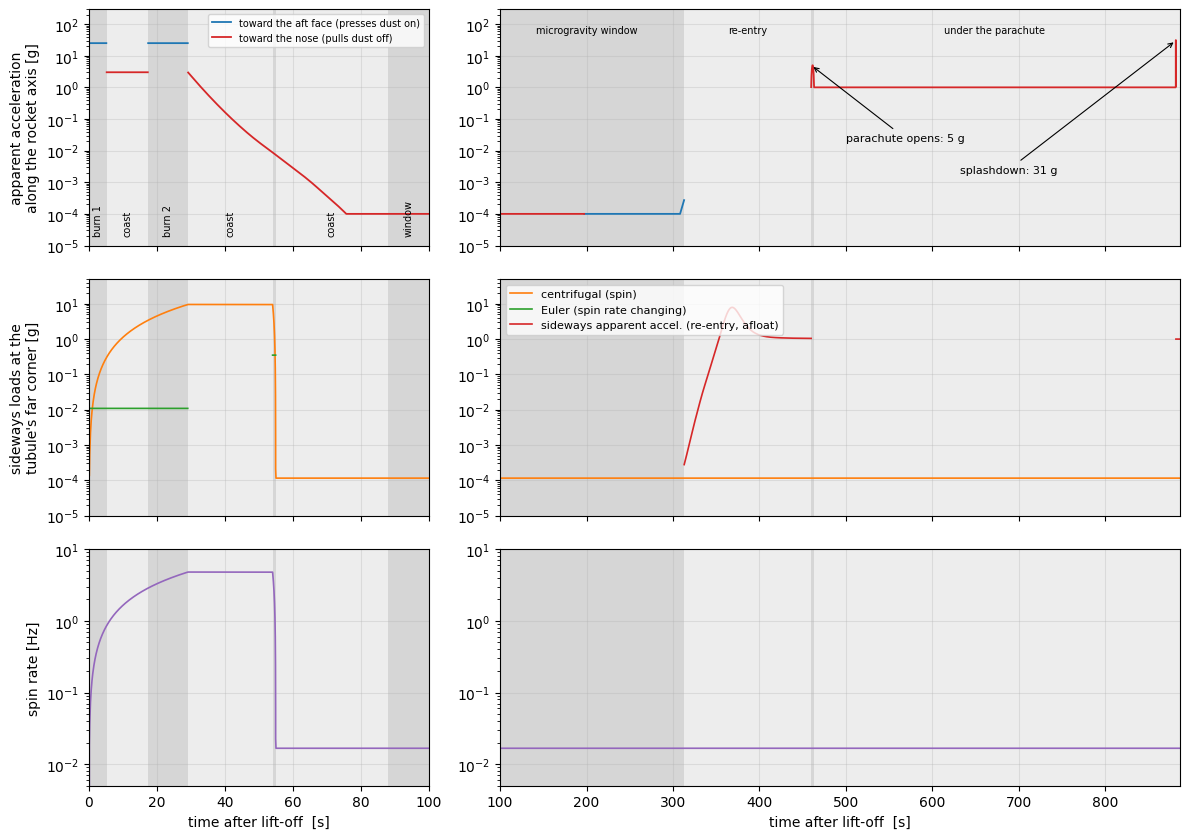

largest: pressing onto the aft face 25.0 g, pulling off 31.2 g, centrifugal 9.56 g, Euler 0.35 g, sideways 7.93 g
coast drag right after the first burn: 3.00 g; in the window: axial 2.7e-04 g, centrifugal 1.2e-04 g


In [5]:
tubules, source = nbf.example_tubules()      # the example payload: configs/mission_quarter_deck.json
r_far = nbf.far_corner(tubules[0])           # T1's far corner [m]
hist = nbf.flight_history(prof, r_far)       # loads sampled through the flight (dense in short events)
fig = nbf.plot_flight(prof, hist)
plt.show()
window = (hist["t"] > prof.ug_start_s) & (hist["t"] < prof.ug_end_s)
print(f"largest: pressing onto the aft face {-hist['axial_g'].min():.1f} g, pulling off {hist['axial_g'].max():.1f} g, "
      f"centrifugal {hist['centrifugal_g'].max():.2f} g, Euler {hist['euler_g'].max():.2f} g, "
      f"sideways {hist['sideways_g'].max():.2f} g")
print(f"coast drag right after the first burn: {hist['axial_g'][(hist['t'] > 5.3) & (hist['t'] < 6)].max():.2f} g; "
      f"in the window: axial {np.abs(hist['axial_g'][window]).max():.1e} g, "
      f"centrifugal {hist['centrifugal_g'][window].max():.1e} g")

**Why this happens.**
* **Burns** (blue, top left): the thrust presses the dust onto the aft face at 25 g. Between and after the burns the
  rocket is slowed by air drag, so the dust is pulled toward the nose (red), by ~3 g at first, fading as the air
  thins.
* **Spin** (bottom): the rocket spins up through the boost to 4.8 Hz; the centrifugal load at the tubule (orange,
  middle) grows as $\Omega^2 r$ to ~10 g, along the aft face. The yo-yo de-spin at T+54 s removes it in 0.9 s,
  with a short Euler load (green) while the spin rate drops.
* **Microgravity window** (T+88 to T+313 s): only the ASSUMED residual $10^{-4}$ g remains, toward the nose until
  apogee and toward the aft face after it (the drag of the thin air reverses with the motion), plus the 1 rpm
  residual spin's ~$10^{-4}$ g. At the very end of the window the drag of the returning air starts to exceed the
  residual (the 2.7×10⁻⁴ g printed above).
* **Re-entry**: the payload falls side-on, so the deceleration (peak 7.9 g) acts sideways (red, middle right).
* **Parachute and splashdown**: hanging nose down under the canopy, the dust is pulled toward the nose by 1 g, by
  5 g while the canopy opens and by 31 g for the 0.05 s of the water impact; afloat on its side, 1 g acts sideways.

## 3. The phases and where each number comes from

In [6]:
rows = [dict(phase=ph["name"], t0=ph["t0"], t1=ph["t1"], f=f"{ph['axial_g_range'][0]:.3g} .. {ph['axial_g_range'][1]:.3g}",
             side=ph["lateral_g_max"], source=ph["source"]) for ph in prof.phases()]
nbf.print_table(rows, [("phase", "phase", ""), ("t0", "from T+ [s]", ".1f"), ("t1", "to T+ [s]", ".2f"),
                       ("f", "specific force along +z [g]", ""), ("side", "sideways [g]", ".3g"),
                       ("source", "source (flight.py)", "")])

phase                          from T+ [s]  to T+ [s]  specific force along +z [g]  sideways [g]  source (flight.py)                                                                        
-----------------------------  -----------  ---------  ---------------------------  ------------  ------------------------------------------------------------------------------------------
first-stage burn               0.0          5.20       25 .. 25                     0             guide                                                                                     
coast between burns            5.2          17.40      -3 .. -3                     0             timing: guide; drag: derived estimate                                                     
second-stage burn              17.4         29.10      25 .. 25                     0             guide                                                                                     
coast in the upper atmosphere  29.1         54.00      

In [7]:
for k in ("burn_g", "lateral_g", "coast_drag_g", "spin_burnout_hz", "despin_s", "despin_duration_s",
          "residual_spin_hz", "residual_g", "ug_start_s", "ug_end_s", "power_off_s", "chute_s",
          "chute_altitude_m", "opening_peak_g", "splash_s", "splash_stop_s", "hang_attitude", "descent_attitude"):
    print(f"{k:20s} {getattr(prof, k)}")

burn_g               25.0
lateral_g            10.0
coast_drag_g         3.0
spin_burnout_hz      4.8
despin_s             54.0
despin_duration_s    0.9
residual_spin_hz     0.016666666666666666
residual_g           0.0001
ug_start_s           88.0
ug_end_s             313.0
power_off_s          332.0
chute_s              460.0
chute_altitude_m     4600.0
opening_peak_g       5.0
splash_s             882.0
splash_stop_s        0.05
hang_attitude        nose_down
descent_attitude     broadside


Note the sign convention of the table: it gives the **specific force** $\mathbf f$ (what an accelerometer reads); the
dust feels $-\mathbf f$. So +25 g during the burns presses the dust onto the aft face, and −31 g at splashdown
(nose down) pulls it off.

| value | source (as cited in `dolle_sim/flight.py`) | status |
|---|---|---|
| burn and coast times, 25 g, chute and splash times, power-off at T+332 s | the launch provider's payload user guide (2026, Rev-A draft), Table 3-1 and Sec. 3.3 | published; 25 g is a design envelope, its flat shape inside each burn is ASSUMED |
| ±10 g lateral during ascent | the same guide, Sec. 5.2.5 | published; used in the load report only |
| spin 4.8 Hz at second-stage burnout | the guide, Table 3-1 | published; the linear spin-up is ASSUMED |
| coast drag 3 g | derived from trajectory points in mission fact sheets of earlier flights of the same vehicle | DERIVED estimate (3–5 g) |
| de-spin at T+54 s in 0.9 s | fact sheets (time); Ettl & Pfaender 2009, symposium paper (yo-yo duration) | published analogues |
| 1 rpm after de-spin | the DOLL-E team's earlier assumption; the guide gives 0–1 Hz (`RESIDUAL_SPIN_OPTIONS_HZ` lists the alternatives) | ASSUMED |
| $10^{-4}$ g residual | order of magnitude of the drag at 100 km (Ettl & Pfaender 2009) | ASSUMED |
| microgravity window T+88 to T+313 s | the 100 km crossings, derived from the fact sheets' apogee time and height | DERIVED |
| re-entry: 7.9 g peak, side-on | point-mass fall through the NRLMSIS 2.1 atmosphere model (Emmert et al. 2021), ballistic coefficient solved to reach 4.6 km at the guide's chute time; integrator checked against Allen & Eggers (1958); side-on attitude from flight data of comparable payloads (Stamminger 2007) | DERIVED; such fall models read somewhat low against measured flights (`flight.py`) |
| chute at 4.6 km, 5 g opening | a mission fact sheet (altitude); report M-EH-75-2 (1975): openings "up to 5 g" | published analogues |
| hanging nose down; afloat on its side | a 2016 student flight report on a related rocket | published analogue |
| splash stopping time 0.05 s | none found | ASSUMED |

## 4. What each phase does to the dust

Notebook 04 gave the limits of a grain resting on the wall: pulled off at $a_{\rm pull} = 9w/(8\rho R^2)$ (hundreds
to thousands of g), rolled at $a_{\rm roll} = (h a_0/3R)\,a_{\rm pull}$ (about 1–11 g). The table compares, for every
phase and example tubule, the load **along** the aft face at the tubule's far corner with the rolling limits of its
largest grain (rolls first) and smallest grain, and the load **pulling** dust off with the largest grain's pull-off
limit (nominal adhesion, `nbf.phase_effects`):

In [8]:
effects = nbf.phase_effects(prof, tubules)
nbf.print_table(effects, [("phase", "phase", ""), ("pull_g", "pull off [g]", ".3g")] +
                [(tb["name"][:2], tb["name"], "") for tb in tubules])
weakest = min(dc.wall_limits(tb["dust"], tb["d_max"] / 2, tb["wall"]).pull_off_g for tb in tubules)
largest_pull = max(row["pull_g"] for row in effects)
print(f"\nlargest pull off the aft face {largest_pull:.1f} g; weakest pull-off limit {weakest:.0f} g "
      f"(margin {weakest / largest_pull:.0f}x)")
weak10 = dc.wall_limits("silica", 106e-6 / 2, "glass_borosilicate", f_adh=math.exp(-1.2816 * 0.6))
print(f"T1's largest grains with one-in-ten weak adhesion: pull-off {weak10.pull_off_g:.0f} g "
      f"(margin {weak10.pull_off_g / largest_pull:.0f}x); nominal rolling limit "
      f"{dc.wall_limits('silica', 106e-6 / 2, 'glass_borosilicate').roll_g:.2f} g")

phase                          pull off [g]  T1_silica_90-106um_bare  T2_graphite_90-106um_bare  T3_silica_45-53um_silanized  T4_graphite_45-53um_silanized
-----------------------------  ------------  -----------------------  -------------------------  ---------------------------  -----------------------------
first-stage burn               0             0.304 g: held            0.236 g: held              0.236 g: held                0.304 g: held                
coast between burns            3             3.41 g: all roll         2.65 g: held               2.65 g: held                 3.41 g: held                 
second-stage burn              0             9.54 g: all roll         7.41 g: all roll           7.41 g: all roll             9.54 g: largest roll         
coast in the upper atmosphere  2.95          9.56 g: all roll         7.43 g: all roll           7.43 g: all roll             9.56 g: largest roll         
de-spin                        0.00874       9.52 g: all roll   

**Why this happens, phase by phase.**
* **Burns**: the 25 g presses the dust on; it raises every limit slightly (by 25 $m g_0$ against $2F_c$, notebook 04).
* **Coast between the burns**: the ~3 g drag pull is under 1 % of the pull-off limits, but the spin is rising,
  and in T1 (90–106 µm silica on bare glass) it passes the rolling limit: the dust starts to roll.
* **Second burn and the coast to de-spin**: at 4.8 Hz the centrifugal load (7.4–9.6 g) exceeds the rolling limits of
  nearly all the example dust; the grains roll to the outer side of the aft face and collect against the side wall
  (notebook 04, section 8). The ±10 g lateral envelope of the guide (not in this table) would do the same.
* **De-spin, the coast and the microgravity window**: the loads fall to ~$10^{-4}$ g; nothing moves the wall dust
  unless the release mechanism does.
* **Re-entry**: 7.9 g sideways rolls the dust again, toward the side that faces forward in the fall.
* **Parachute (5 g) and splashdown (31 g)**: pull the dust off the aft face, far below pull-off: **nothing comes
  off at any phase**, with a margin (printed above) of about 29× for the weakest example grains at nominal
  adhesion and still about 14× for T1's one-in-ten weakly bound grains.
* **Afloat**: 1 g sideways, just below the 1.13 g rolling limit of T1's largest grains at nominal adhesion (grains
  with weak adhesion would roll).

So the launch rearranges the dust (rolling) but does not free it: what the experiment starts from in the window is
dust piled against the tubules' outer walls, and only a release mechanism can put it in flight.

## 5. What the full simulator has found so far

The scenario table below is **from the v0.5 engine** (README, "Mission runs"). The v0.5 engine treats stuck grains as
rigid aggregates and holds wall grains in place until they are pulled off, so it has **no rolling or sliding along
the walls**: the rearrangement of section 4 is missing from it. The v0.6 full-contact engine models rolling, but its
re-runs of the scenarios were **stopped** before they finished, so there are no v0.6 scenario results. Each cell is
*grains released · grain–grain impacts in the microgravity window (single-grain impacts that stuck / all single-grain
impacts, their median speed)*, for 800 example grains per tubule.

In [9]:
print(nbf.V05_STATUS, "\n")
for sc, desc, *cells in nbf.V05_SCENARIOS:
    print(f"{sc:15s} {desc}")
    print("    " + " | ".join(f"{tb['name'][:2]} {c}" for tb, c in zip(tubules, cells)))
print("\nthis copy equals README.md's table:", nbf.v05_table_matches_readme())   # None: README not on disk (Colab)

v0.5 event-driven engine: rigid aggregates; wall grains held in place until pulled off, so no rolling or sliding along the walls; 800 grains per tubule; README.md 'Mission runs' table (commit f133c3e). The v0.6 full-contact re-runs were stopped before they finished: there are no v0.6 scenario results. 

nominal         50 g / 200 Hz shaker, 10 s at T+90 s (vacuum, standing)
    T1 0 · 0 | T2 0 · 0 | T3 0 · 0 | T4 0 · 0
no_release      no release mechanism
    T1 0 · 0 | T2 0 · 0 | T3 0 · 0 | T4 0 · 0
no_drag         nominal, no drag in the coasts
    T1 0 · 0 | T2 0 · 0 | T3 0 · 0 | T4 0 · 0
rough_grains    nominal, stickiness × 0.02 (rough grains or a coating)
    T1 730 · 7051 (223/6189, 471 mm/s) | T2 588 · 3534 (117/2712, 449 mm/s) | T3 398 · 637 (39/368, 452 mm/s) | T4 179 · 124 (4/28, 421 mm/s)
strong_shaker   500 g / 1 kHz shaker, 5 s at T+90 s
    T1 88 · 125 (0/39, 1071 mm/s) | T2 28 · 36 (0/2, 882 mm/s) | T3 6 · 0 | T4 0 · 0
kick            three 5,000 g / 5 kHz single-cycle 

In [10]:
kicks = [nbf.parse_v05_cell(c) for sc, _, *cells in nbf.V05_SCENARIOS if sc in ("kick", "kick+lying") for c in cells]
print(f"kicks in vacuum (standing or lying): grain-grain impacts per tubule {min(k['impacts'] for k in kicks)}-"
      f"{max(k['impacts'] for k in kicks)}, median single-grain impact speed {min(k['median_mm_s'] for k in kicks)}-"
      f"{max(k['median_mm_s'] for k in kicks)} mm/s, stuck {sum(k['stuck'] for k in kicks)} of "
      f"{sum(k['singles'] for k in kicks)} single-grain impacts")

kicks in vacuum (standing or lying): grain-grain impacts per tubule 25-239, median single-grain impact speed 12-160 mm/s, stuck 53 of 259 single-grain impacts


**Reading it.** On clean or silanised glass, the 50 g shaker frees nothing and only the 5,000 g kicks free most of
the dust (notebook 04: the pull-off limits are hundreds to thousands of g). After the kicks there are a few tens to a
few hundred grain–grain impacts per tubule in the window, at median speeds from about 12 to 160 mm/s, and few of
them stick. A residual spin of 1 Hz gives many more impacts but faster ones; gas stops the kicked grains within a
fraction of a second (README, "Mission runs": only 1–57 impacts per tubule with gas); weakly bound dust (`rough_grains`) is freed by the shaker, but the shaking walls keep it fast.

## 6. What DOLL-E can measure in the microgravity window

A measurement of the sticking speed needs impacts **around** the sticking speed (some below it, some above), measured
well enough, before the walls catch the grains. Four numbers decide it.

**(a) The sticking speeds themselves** (notebook 03 explains them): two equal grains, the simulator's material values,
at the sieve limits of the example dust:

In [11]:
for grain in ("silica", "graphite"):
    for d in (45e-6, 53e-6, 90e-6, 106e-6):
        v = dc.sticking_threshold(dc.make_pair(grain, d / 2, grain, d / 2))
        print(f"{grain:8s} d = {d * 1e6:3.0f} um: sticks below {v * 1e3:5.1f} mm/s")

silica   d =  45 um: sticks below  12.0 mm/s
silica   d =  53 um: sticks below  10.5 mm/s
silica   d =  90 um: sticks below   6.7 mm/s
silica   d = 106 um: sticks below   5.9 mm/s
graphite d =  45 um: sticks below  74.5 mm/s
graphite d =  53 um: sticks below  65.0 mm/s
graphite d =  90 um: sticks below  41.9 mm/s


graphite d = 106 um: sticks below  36.5 mm/s


**Why this happens.** Smaller grains stick at higher speeds ($v\propto R^{-5/6}$, notebook 03), and graphite at about
six times silica's speed. So the four example tubules span about a factor of twelve in sticking speed.

**(b) The impact speeds the release produces.** The plot puts the v0.5 median impact speeds (kicks, standing and lying)
next to these sticking speeds, with how many of the single-grain impacts stuck:

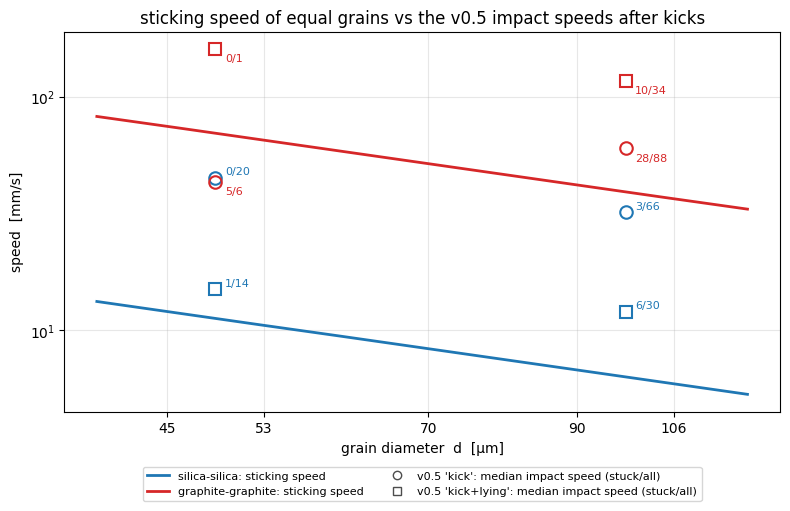

In [12]:
ax = nbf.plot_thresholds_and_impacts(tubules)
ax.set_title("sticking speed of equal grains vs the v0.5 impact speeds after kicks")
plt.show()

**Why this happens.** The simulated outcomes follow the sticking speeds: where the median impact is well above the
line (silica after standing kicks, 32–45 mm/s against ~6–12 mm/s) almost nothing sticks; where it is below the line
(45–53 µm graphite after standing kicks, 43 mm/s against ~65 mm/s) most impacts stick (5 of 6, so few that this
is only an indication). A threshold measurement needs
both in the same tubule, so the release must give impacts **closer to the sticking speeds**: gentler (a higher kick
frequency, notebook 04 section 8) or slowed afterwards.

**(c) The walls.** Even without impacts, the residual acceleration $a$ drives every free grain into a wall: from rest
across a distance $L$ it takes $t=\sqrt{2L/a}$ and arrives at $v=\sqrt{2aL}$ (constant acceleration). The worst case
is the tubule's full length along the rocket axis, read from the example config (`inner_size_in`). Compare with the
speed below which a grain sticks to the **wall** (sphere on a flat: `dc.make_pair` with the second radius omitted;
the same numbers as `examples/sticking_threshold.py`):

In [13]:
a_res = prof.residual_g * G0                                   # [m/s^2]
L_tube = tubules[0]["inner_size_in"][2] * 0.0254              # tubule length [m] along the rocket axis (config)
print(f"residual {prof.residual_g:g} g over {L_tube * 1e3:.1f} mm: {math.sqrt(2 * L_tube / a_res):.1f} s, "
      f"arriving at {math.sqrt(2 * a_res * L_tube) * 1e3:.1f} mm/s")
spin_load = np.hypot(*prof.loads_at(200.0, r_far)["centrifugal"][:2])
print(f"1 rpm residual spin at T1's far corner: {spin_load:.2e} g (centrifugal)")
for grain, wall in (("silica", "glass_borosilicate"), ("graphite", "glass_borosilicate"),
                    ("silica", "glass_silanized"), ("graphite", "glass_silanized")):
    v = dc.sticking_threshold(dc.make_pair(grain, 50e-6, wall))
    print(f"{grain:8s} (d = 100 um) on {wall:18s} sticks below {v * 1e3:5.2f} mm/s")

residual 0.0001 g over 38.1 mm: 8.8 s, arriving at 8.6 mm/s
1 rpm residual spin at T1's far corner: 1.15e-04 g (centrifugal)
silica   (d = 100 um) on glass_borosilicate sticks below  6.66 mm/s
graphite (d = 100 um) on glass_borosilicate sticks below 18.23 mm/s
silica   (d = 100 um) on glass_silanized    sticks below  4.23 mm/s
graphite (d = 100 um) on glass_silanized    sticks below 11.56 mm/s


**Why this happens.** The residual $10^{-4}$ g sounds negligible, but over a tubule's length it accelerates a grain to
the same few mm/s at which grains stick to glass. The worst case, 8.6 mm/s over the full length, is above the
6.66 mm/s at which 100 µm silica sticks to bare borosilicate (and the 4.23 mm/s on silanised glass), so such a grain
bounces once and is caught on its next, slower contact (next cell; the residual acceleration brings it back). Graphite
(18.2 mm/s on bare glass) sticks at once. Free grains in bare tubules are therefore collected by the walls within
seconds to tens of seconds unless the walls are made less sticky (coatings, roughening) or kept moving: the
README's section "Keeping grains off the walls" describes the options and marks their values as ASSUMED.

In [14]:
v_arrive = math.sqrt(2 * a_res * L_tube)                       # worst case: the full length [m/s]
first = dc.collide("silica", 50e-6, "glass_borosilicate", None, u1=v_arrive)
second = dc.collide("silica", 50e-6, "glass_borosilicate", None, u1=first.e * v_arrive)
print(f"silica on bare borosilicate at {v_arrive * 1e3:.1f} mm/s: {first.outcome} (e = {first.e:.3f}); "
      f"back at {first.e * v_arrive * 1e3:.1f} mm/s: {second.outcome}")

silica on bare borosilicate at 8.6 mm/s: bounce (e = 0.457); back at 4.0 mm/s: stick


**(d) The camera.** The impact speed is measured from the grains' tracks. A least-squares straight-line fit through
$k$ frames at frame rate $f_{\rm cam}$ with a position error $\sigma_x$ per frame gives a velocity error
$\sigma_x f_{\rm cam}\sqrt{12/(k(k^2-1))}$ per grain and axis (standard least-squares slope error); the relative speed
of two grains has $\sqrt2$ times that (`dolle_sim/analysis.py`). With the example camera of
`configs/mission_quarter_deck.json` (EXAMPLE values, read below):

In [15]:
cam = nbf.example_camera()                                       # EXAMPLE values from the config
sigma_x, fps, k = cam["position_noise_m"], cam["fps"], cam["track_frames"]
print(f"example camera: {fps} frames/s, {sigma_x * 1e6:g} um per frame, {k} frames per fit")
sigma_v = math.sqrt(2) * sigma_x * fps * math.sqrt(12 / (k * (k * k - 1)))
v_si = dc.sticking_threshold(dc.make_pair("silica", 50e-6, "silica", 50e-6))
print(f"relative-speed error per axis {sigma_v * 1e3:.2f} mm/s = {sigma_v / v_si:.0%} of the 100 um silica "
      f"sticking speed ({v_si * 1e3:.2f} mm/s)")
print(f"with 1 um centroids: {sigma_v / 5 * 1e3:.2f} mm/s")

example camera: 500 frames/s, 5 um per frame, 6 frames per fit
relative-speed error per axis 0.85 mm/s = 14% of the 100 um silica sticking speed (6.18 mm/s)
with 1 um centroids: 0.17 mm/s


**Why this happens.** A fit through more frames or a more precise centroid shrinks the error; a faster camera with
the same number of frames makes it **worse** (the frames are closer together, so the same position error means a
larger velocity error). At the silica sticking speed this error is not small, so the speed of each impact must be
measured in 3-D (two camera views) and with good centroids (README, "Measurement").

## What to remember

* Inside the payload a free grain feels minus the accelerometer reading ($-\mathbf f$), not gravity: thrust presses
  the dust onto the aft face at 25 g, drag pulls it off at a few g, and above ~100 km only ~$10^{-4}$ g remains for
  about 225 s.
* The spin (4.8 Hz, ~10 g sideways at the tubules) and the side-on re-entry (7.9 g) exceed the rolling limits: the
  dust **rolls** along the walls. No load (largest: 31 g at splashdown) comes near the pull-off limits: **nothing
  comes off by itself**.
* The scenario results are from the **v0.5 engine** (no rolling along walls); the v0.6 full-contact runs were
  stopped. In v0.5 only 5,000 g kicks free the dust, and they make impacts mostly faster than the sticking speeds.
* A measurement needs impacts near the sticking speeds (~6 to ~75 mm/s for the example dust), walls that do not
  collect the grains at the few mm/s the residual acceleration gives them, and 3-D speeds better than ~1 mm/s.

## Check it yourself

1. Make a profile with the guide's upper residual spin, `FlightProfile(residual_spin_hz=1.0)`, and compute the
   centrifugal load at T1's far corner in the window (`prof1.loads_at(200.0, r_far)`). Compare it with the
   $10^{-4}$ g residual: which one now drives the grains into the walls, and how fast do they arrive across the
   tubule's 12.7 mm width?
2. With `FlightProfile(splash_stop_s=0.2)` the splash is four times longer. What is its peak now, and does it change
   any conclusion of section 4?

In [16]:
# your turn, e.g.:
# prof1 = FlightProfile(residual_spin_hz=1.0)
# print(np.hypot(*prof1.loads_at(200.0, r_far)["centrifugal"][:2]), "g")